**Prompts in Gemini:**

based on this formula, create a simulation to graph the interest rates paid against the total amount for a mortgage of 70000 EUR, with a fixed interest rate of 2 and 1.5% and 20 years.


*Insert the screenshot of the french amortization system formula.*


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def calculate_mortgage(principal, annual_rate, years):
    # Monthly interest rate
    r = annual_rate / 100 / 12
    # Number of payments
    n = years * 12

    # Amortization formula for monthly payment
    # M = P * [r(1+r)^n] / [(1+r)^n - 1]
    if r == 0:
        monthly_payment = principal / n
    else:
        monthly_payment = principal * (r * (1 + r)**n) / ((1 + r)**n - 1)

    total_paid = monthly_payment * n
    total_interest = total_paid - principal
    return monthly_payment, total_interest, total_paid

# Parameters
principal = 70000
years = 20
rates = [1.5, 2.0]

results = []
for rate in rates:
    m_pay, t_int, t_paid = calculate_mortgage(principal, rate, years)
    results.append({
        'Interest Rate (%)': f"{rate}%",
        'Monthly Payment (€)': m_pay,
        'Total Interest Paid (€)': t_int,
        'Total Paid (€)': t_paid
    })

df = pd.DataFrame(results)
display(df.round(2))


,Interest Rate (%),Monthly Payment (€),Total Interest Paid (€),Total Paid (€)
0,1.5%,337.78,11067.63,81067.63
1,2.0%,354.12,14988.40,84988.40


**Prompt:**

now, simulate this with random values of variable rates ranging between 0 and 3%.


calculate and graph the cumulative interest paid over time for the simulated variable and the fixed rates

--- Variable Rate Simulation Summary ---
Average Simulated Interest Rate: 1.16%
Total Interest Paid (Variable): €8,381.07
Total Amount Paid (Variable): €78,381.07



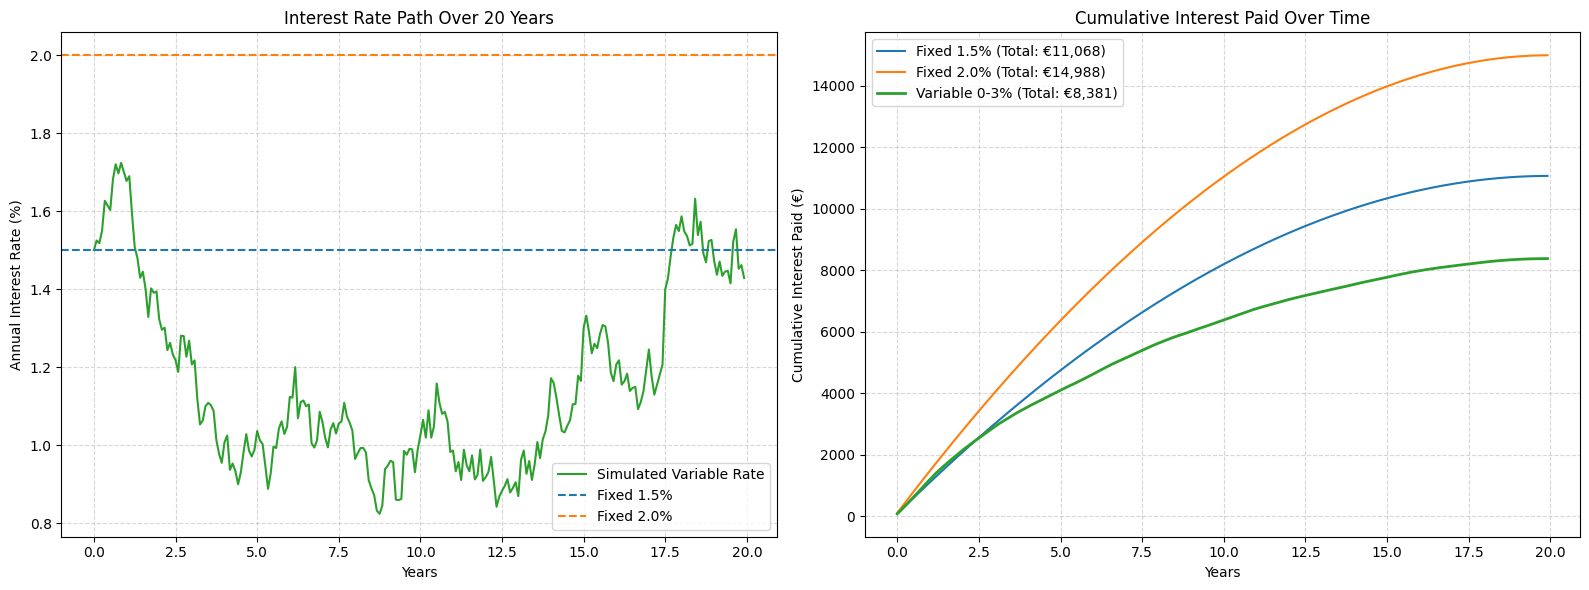

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Parameters
principal = 70000
years = 20
months = years * 12

# Generate a random path for variable interest rate between 0% and 3% (changing monthly)
np.random.seed(42)  # Set seed for reproducibility
# We will use a random walk bounded between 0% and 3% to simulate realistic market fluctuations
rates_path = [1.5]  # Start at 1.5%
for _ in range(1, months):
    change = np.random.normal(0, 0.05)  # Small monthly changes
    next_rate = np.clip(rates_path[-1] + change, 0.0, 3.0)
    rates_path.append(next_rate)

# Calculate monthly payments for the variable rate scenario
remaining_principal = principal
variable_monthly_payments = []
variable_interest_paid = []
variable_principal_paid = []

for i in range(months):
    r_annual = rates_path[i]
    r_monthly = r_annual / 100 / 12
    months_remaining = months - i

    if r_monthly == 0:
        payment = remaining_principal / months_remaining
    else:
        payment = remaining_principal * (r_monthly * (1 + r_monthly)**months_remaining) / ((1 + r_monthly)**months_remaining - 1)

    interest_payment = remaining_principal * r_monthly
    principal_payment = payment - interest_payment

    variable_monthly_payments.append(payment)
    variable_interest_paid.append(interest_payment)
    variable_principal_paid.append(principal_payment)

    remaining_principal -= principal_payment

total_variable_interest = sum(variable_interest_paid)
total_variable_paid = principal + total_variable_interest

# Append variable results to our previous comparison
print(f"--- Variable Rate Simulation Summary ---")
print(f"Average Simulated Interest Rate: {np.mean(rates_path):.2f}%")
print(f"Total Interest Paid (Variable): €{total_variable_interest:,.2f}")
print(f"Total Amount Paid (Variable): €{total_variable_paid:,.2f}\n")

# Create comparison visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Left Plot: Interest Rate Path Over Time
ax1.plot(np.arange(months) / 12, rates_path, label='Simulated Variable Rate', color='#2ca02c')
ax1.axhline(1.5, color='#1f77b4', linestyle='--', label='Fixed 1.5%')
ax1.axhline(2.0, color='#ff7f0e', linestyle='--', label='Fixed 2.0%')
ax1.set_xlabel('Years')
ax1.set_ylabel('Annual Interest Rate (%)')
ax1.set_title('Interest Rate Path Over 20 Years')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# Right Plot: Cumulative Interest Paid Comparison
fixed_15_monthly = [calculate_mortgage(principal, 1.5, years)[0]] * months
fixed_20_monthly = [calculate_mortgage(principal, 2.0, years)[0]] * months

def get_cumulative_interest(monthly_pmts, rate_values):
    rem_p = principal
    cum_int = []
    total_int = 0
    for i in range(months):
        r_m = (rate_values[i] if isinstance(rate_values, list) else rate_values) / 100 / 12
        interest = rem_p * r_m
        total_int += interest
        rem_p -= (monthly_pmts[i] - interest)
        cum_int.append(total_int)
    return cum_int

cum_int_15 = get_cumulative_interest(fixed_15_monthly, 1.5)
cum_int_20 = get_cumulative_interest(fixed_20_monthly, 2.0)
cum_int_var = np.cumsum(variable_interest_paid)

ax2.plot(np.arange(months) / 12, cum_int_15, label='Fixed 1.5% (Total: €11,068)', color='#1f77b4')
ax2.plot(np.arange(months) / 12, cum_int_20, label='Fixed 2.0% (Total: €14,988)', color='#ff7f0e')
ax2.plot(np.arange(months) / 12, cum_int_var, label=f'Variable 0-3% (Total: €{total_variable_interest:,.0f})', color='#2ca02c', linewidth=2)
ax2.set_xlabel('Years')
ax2.set_ylabel('Cumulative Interest Paid (€)')
ax2.set_title('Cumulative Interest Paid Over Time')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Prompt:**

Now, calculate the monthly fees to pay for both the fixed and variable interest rates

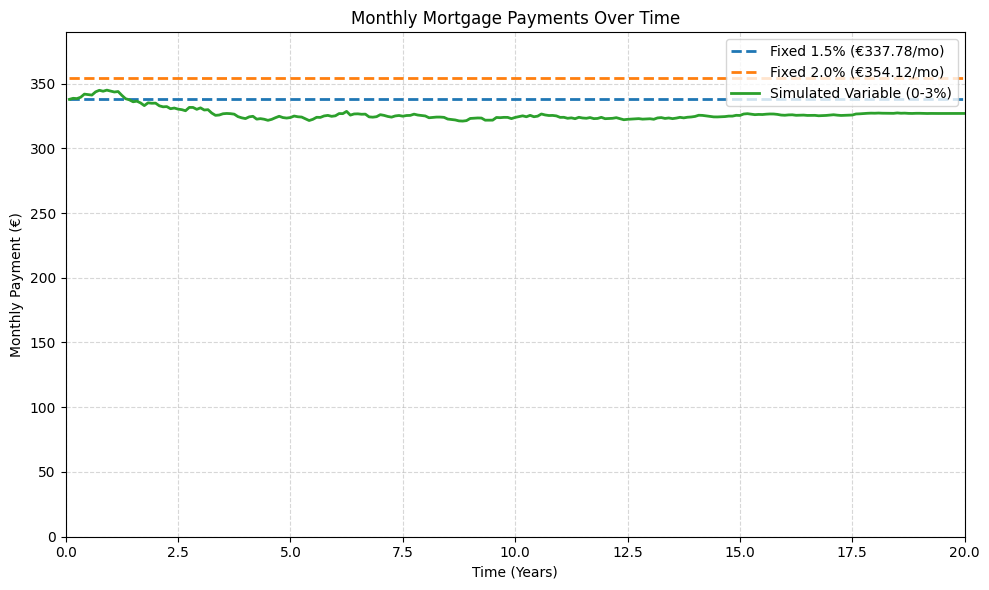

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
principal = 70000
years = 20
months = years * 12
time_axis = np.arange(1, months + 1) / 12  # Convert months to years

# Re-calculate the fixed monthly payments using the formula defined in cell 43a6cb83
monthly_payment_15, _, _ = calculate_mortgage(principal, 1.5, years)
monthly_payment_20, _, _ = calculate_mortgage(principal, 2.0, years)

# Calculate monthly payments for fixed rates (constant over 20 years)
fixed_15_payments = [monthly_payment_15] * months
fixed_20_payments = [monthly_payment_20] * months

# Plotting the monthly payments (fees)
plt.figure(figsize=(10, 6))

plt.plot(time_axis, fixed_15_payments, label=f'Fixed 1.5% (€{monthly_payment_15:.2f}/mo)', color='#1f77b4', linewidth=2, linestyle='--')
plt.plot(time_axis, fixed_20_payments, label=f'Fixed 2.0% (€{monthly_payment_20:.2f}/mo)', color='#ff7f0e', linewidth=2, linestyle='--')
plt.plot(time_axis, variable_monthly_payments, label='Simulated Variable (0-3%)', color='#2ca02c', linewidth=2)

plt.title('Monthly Mortgage Payments Over Time')
plt.xlabel('Time (Years)')
plt.ylabel('Monthly Payment (€)')
plt.xlim(0, years)
plt.ylim(0, max(max(fixed_20_payments), max(variable_monthly_payments)) * 1.1)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()